# 🧲 MAXWELL TOOLS - Conversão de Unidades Eletromagnéticas

---
Copyright (C) 2026 Roberto Baginski Batista Santos - Prof.Baginski@gmail.com

Este programa é um software livre; você pode redistribuí-lo e/ou
modificá-lo sob os termos da Licença Pública Geral GNU como publicada
pela Free Software Foundation; tanto a versão 3 da Licença, ou
(a seu critério) qualquer versão posterior.

Este programa é distribuído na expectativa de que seja útil,
mas SEM NENHUMA GARANTIA; sem mesmo a garantia implícita de
COMERCIALIZAÇÃO ou de ADEQUAÇÃO A QUALQUER PROPÓSITO EM PARTICULAR.
Veja a Licença Pública Geral GNU para mais detalhes.

Você deve ter recebido uma cópia da Licença Pública Geral GNU junto
com este programa. Se não, veja https://www.gnu.org/licenses/gpl-3.0.html.

---
Esta ferramenta **converte grandezas eletromagnéticas** entre cinco sistemas de unidades:

1. **Sistema Internacional (SI)**
2. **Gaussiano** (combinação dos sistemas CGS-EMU e CGS-ESU)
3. **CGS-EMU** (sistema eletromagnético)
4. **CGS-ESU** (sistema eletrostático)
5. **Heaviside-Lorentz** (sistema Gaussiano racionalizado)

Com a revisão de 2019 do Sistema Internacional, a permeabilidade magnética do vácuo $\mu_0$ deixou de valer exatamente $4\pi\times 10^{-7}\mathrm{H}/\mathrm{m}$ e passou a ser calculada por $\mu_0 = 2\alpha h/e^2 c$, em que $e$ é a carga elementar, $h$ é a constante de Planck, $c$ é a velocidade da luz no vácuo e $\alpha$ é a constante de estrutura fina.

A interface apresenta as seguintes abas: *Converter* · *Constantes* ($e$, $c$, $h$, $\hbar$, $\alpha$, $\mu_\mathrm{B}$, $\mu_\mathrm{N}$, $\varepsilon_0$ e $\mu_0$ nos 5 sistemas) · *Equações* (as equações de Maxwell e as relações constitutivas em cada sistema) · *Fatores de Conversão*.

---
**Como usar:** execute a célula 1. Os valores numéricos podem ser expressos com vírgula ou com ponto decimal e você pode usar notação científica (`2,5e-3`, `3,2×10^-4`).

---
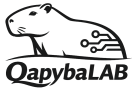  
**https://github.com/rbaginski/QapybaLAB**


In [ ]:
#@title Execute esta célula para abrir a ferramenta **MAXWELL TOOLS &mdash; Conversão de Unidades Eletromagnéticas**
# ── Célula 1: Conversão de Unidades Eletromagnéticas ───────────────────
# A ferramenta foi especificada pelo licenciante, incluindo modelos, métodos,
# pacotes a serem usados e linhas gerais da inteface gráfica, mas a maior parte
# do código, especialmente as funções para leitura de arquivos e para a
# interface gráfica, foi escrita usando o modelo Claude Opus 5.5.
# O código gerado foi inspecionado e sofreu alterações realizadas pelo licenciante.

# ============================================================================
#  MOTOR DE CONVERSÃO — sistemas de unidades eletromagnéticas
# ============================================================================
import math
from fractions import Fraction as Fr

# ---------------------------------------------------------------------------
# 1. Constantes: SI revisado (2019) + CODATA 2022
# ---------------------------------------------------------------------------
# Exatas (definem o SI desde 20/05/2019)
c_SI    = 299_792_458.0                 # m/s
h_SI    = 6.626_070_15e-34              # J s
e_SI    = 1.602_176_634e-19             # C
hbar_SI = h_SI / (2 * math.pi)          # J s
# Medidas (CODATA 2022)
ALPHA,  U_ALPHA = 7.297_352_5643e-3, 0.000_000_0011e-3   # estrutura fina
ME_SI,  U_ME    = 9.109_383_7139e-31, 0.000_000_0028e-31 # kg
MP_SI,  U_MP    = 1.672_621_925_95e-27, 0.000_000_000_52e-27  # kg
MUB_SI, U_MUB   = 9.274_010_0657e-24, 0.000_000_0029e-24 # J/T
MUN_SI, U_MUN   = 5.050_783_7393e-27, 0.000_000_0016e-27 # J/T
MU0_CODATA, U_MU0 = 1.256_637_061_27e-6, 0.000_000_000_20e-6  # N/A²
EPS0_CODATA, U_EPS0 = 8.854_187_8188e-12, 0.000_000_0014e-12  # F/m

# μ0 = 2αh/(e²c);  ε0 = 1/(μ0 c²)
MU0_SI  = 2 * ALPHA * h_SI / (e_SI**2 * c_SI)
EPS0_SI = 1 / (MU0_SI * c_SI**2)
UR_MU0  = U_ALPHA / ALPHA             # u_r(μ0) = u_r(ε0) = u_r(α)
# SI anterior a 2019 (para comparação)
MU0_OLD  = 4 * math.pi * 1e-7
EPS0_OLD = 1 / (MU0_OLD * c_SI**2)

# ---------------------------------------------------------------------------
# 2. Álgebra dimensional
#    SI: expoentes (m, kg, s, A)   |   CGS: expoentes (cm, g, s)
# ---------------------------------------------------------------------------
class D:
    """Dimensão (tupla de expoentes racionais)."""
    def __init__(self, *e): self.e = tuple(Fr(x) for x in e)
    def __mul__(self, o): return D(*[a + b for a, b in zip(self.e, o.e)])
    def __truediv__(self, o): return D(*[a - b for a, b in zip(self.e, o.e)])
    def __pow__(self, p): return D(*[a * Fr(p) for a in self.e])
    def __eq__(self, o): return self.e == o.e
    def __hash__(self): return hash(self.e)
    def __repr__(self): return f"D{self.e}"

# --- SI
m_, kg_, s_, A_ = D(1,0,0,0), D(0,1,0,0), D(0,0,1,0), D(0,0,0,1)
ONE_SI = D(0,0,0,0)
N_ = kg_*m_/s_**2; J_ = N_*m_; W_ = J_/s_; C_ = A_*s_; V_ = J_/C_
T_ = V_*s_/m_**2; Wb_ = V_*s_; Ohm_ = V_/A_; S_ = ONE_SI/Ohm_
F_ = C_/V_; H_ = Wb_/A_
# --- CGS
cm_, g_, sc_ = D(1,0,0), D(0,1,0), D(0,0,1)
ONE_CGS = D(0,0,0)
dyn_ = g_*cm_/sc_**2; erg_ = dyn_*cm_
statC_ = (dyn_*cm_**2)**Fr(1,2);  statA_ = statC_/sc_;  statV_ = erg_/statC_
abA_ = dyn_**Fr(1,2);             abC_ = abA_*sc_;      abV_ = erg_/abC_
G_ = (erg_/cm_**3)**Fr(1,2)        # gauss: B²/8π é energia/volume
Oe_ = G_; Mx_ = G_*cm_**2
statT_ = statV_*sc_/cm_**2;  statWb_ = statV_*sc_
statOhm_ = statV_/statA_;  statS_ = ONE_CGS/statOhm_
statF_ = statC_/statV_;    statH_ = statV_*sc_/statA_
abOhm_ = abV_/abA_; abS_ = ONE_CGS/abOhm_; abF_ = abC_/abV_; abH_ = abV_*sc_/abA_

# ---------------------------------------------------------------------------
# 3. Os cinco sistemas, caracterizados por três parâmetros (monômios)
#    kq : q_sis = kq · q_SI            (fator da carga)
#    β  : F = q(E + v×B/β)   e   ∇×E = −(1/β)∂B/∂t
#    κ  : ∇·D = κρ ,  D = ε₀E + κP ,  B = μ₀(H + κM)
#    Monômios sobre a base {q4 = 4π, e0 = ε₀, m0 = μ₀, c}
# ---------------------------------------------------------------------------
SISTEMAS = ['SI', 'GAU', 'EMU', 'ESU', 'HL']          # ordem de apresentação
NOME_SIS = {'SI': 'Sistema Internacional (SI)', 'GAU': 'Gaussiano',
            'EMU': 'CGS-EMU (eletromagnético)', 'ESU': 'CGS-ESU (eletrostático)',
            'HL': 'Heaviside-Lorentz'}
CURTO = {'SI': 'SI', 'GAU': 'G', 'EMU': 'EMU', 'ESU': 'ESU', 'HL': 'HL'}
h_ = Fr(1, 2)
PARAM = {
    'SI':  dict(kq={},                        beta={},       kappa={}),
    'GAU': dict(kq={'q4': -h_, 'e0': -h_},     beta={'c': 1}, kappa={'q4': 1}),
    'ESU': dict(kq={'q4': -h_, 'e0': -h_},     beta={},       kappa={'q4': 1}),
    'EMU': dict(kq={'q4': -h_, 'e0': -h_, 'c': -1}, beta={}, kappa={'q4': 1}),
    'HL':  dict(kq={'e0': -h_},                beta={'c': 1}, kappa={}),
}

def mono_mul(*ms):
    out = {}
    for m in ms:
        for k, v in m.items():
            out[k] = out.get(k, 0) + Fr(v)
    return {k: v for k, v in out.items() if v != 0}

def mono_pow(m, p): return {k: Fr(v) * Fr(p) for k, v in m.items() if v != 0}

def mono_div(a, b): return mono_mul(a, mono_pow(b, -1))

def canonico(m):
    """Elimina c usando c² = 1/(ε₀μ₀): forma única em {4π, ε₀, μ₀}."""
    m = dict(m); f = m.pop('c', 0)
    if f:
        m['e0'] = m.get('e0', 0) - Fr(f, 2)
        m['m0'] = m.get('m0', 0) - Fr(f, 2)
    return {k: v for k, v in m.items() if v != 0}

# Tipos de grandeza: expoentes (a, b, d) em  kq^a · β^b · κ^d
TIPO = {
    'Q':   (1, 0, 0),   # carga, correntes, densidades de carga/corrente, p
    'E':   (-1, 0, 0),  # E, potencial V, fluxo elétrico
    'D':   (1, 0, 1),
    'P':   (1, 0, 0),
    'B':   (-1, 1, 0),  # B, fluxo magnético, potencial vetor A
    'H':   (1, -1, 1),
    'M':   (1, -1, 0),  # magnetização, momento magnético
    'MEC': (0, 0, 0),   # grandezas mecânicas
    'MU':  (-2, 2, -1), # μ = B/H
    'EPS': (2, 0, 1),   # ε = D/E
    'CHI': (0, 0, -1),  # susceptibilidades
    'ADIM': (0, 0, 0),  # εr, μr
    'R':   (-2, 0, 0),  # R, ρ (resistividade), L
    'C':   (2, 0, 0),   # C, σ (condutividade), condutância
}

def monomio(sis, tipo):
    a, b, d = TIPO[tipo]; P = PARAM[sis]
    return canonico(mono_mul(mono_pow(P['kq'], a), mono_pow(P['beta'], b),
                             mono_pow(P['kappa'], d)))

def avalia(m, mu0=MU0_SI):
    """Valor numérico (no SI) e dimensão SI de um monômio."""
    eps0 = 1 / (mu0 * c_SI**2)
    base = {'q4': (4*math.pi, ONE_SI), 'e0': (eps0, D(-3,-1,4,2)),
            'm0': (mu0, D(1,1,-2,-2)), 'c': (c_SI, D(1,0,-1,0))}
    v, dim = 1.0, ONE_SI
    for k, p in m.items():
        bv, bd = base[k]; v *= bv ** float(p); dim = dim * bd**p
    return v, dim

def n_mu0(m):
    """Expoente efetivo de μ₀ (ε₀ ∝ 1/μ₀) → u_r(fator) = |n|·u_r(μ₀)."""
    m = canonico(m); return m.get('m0', 0) - m.get('e0', 0)

# ---------------------------------------------------------------------------
# 4. Grandezas
#    (chave, nome, símbolo HTML, grupo, tipo, {sis: (rótulo, dimensão, alt)})
#    rótulo None em HL → gerado a partir das unidades de base CGS
# ---------------------------------------------------------------------------
ADIM_U = ('—', None, 'adimensional')
def U(r, d, alt=''): return (r, d, alt)
def mec(si, cgs, alt=''):
    return {'SI': U(*si), **{s: U(*cgs, alt) for s in ('GAU', 'EMU', 'ESU', 'HL')}}

GRANDEZAS = [
 # ---------------- Campos
 ('E', 'Campo elétrico', 'E', 'Campos', 'E',
  {'SI': U('V/m', V_/m_), 'GAU': U('statV/cm', statV_/cm_), 'EMU': U('abV/cm', abV_/cm_),
   'ESU': U('statV/cm', statV_/cm_), 'HL': U(None, statV_/cm_)}),
 ('D', 'Deslocamento elétrico', 'D', 'Campos', 'D',
  {'SI': U('C/m²', C_/m_**2), 'GAU': U('statC/cm²', statC_/cm_**2), 'EMU': U('abC/cm²', abC_/cm_**2),
   'ESU': U('statC/cm²', statC_/cm_**2), 'HL': U(None, statC_/cm_**2)}),
 ('P', 'Polarização', 'P', 'Campos', 'P',
  {'SI': U('C/m²', C_/m_**2), 'GAU': U('statC/cm²', statC_/cm_**2), 'EMU': U('abC/cm²', abC_/cm_**2),
   'ESU': U('statC/cm²', statC_/cm_**2), 'HL': U(None, statC_/cm_**2)}),
 ('B', 'Campo magnético (indução magnética)', 'B', 'Campos', 'B',
  {'SI': U('T', T_), 'GAU': U('G', G_), 'EMU': U('G', G_),
   'ESU': U('statT', statT_), 'HL': U(None, G_)}),
 ('H', 'Campo magnético H', 'H', 'Campos', 'H',
  {'SI': U('A/m', A_/m_), 'GAU': U('Oe', Oe_), 'EMU': U('Oe', Oe_),
   'ESU': U('statA/cm', statA_/cm_), 'HL': U(None, Oe_)}),
 ('M', 'Magnetização', 'M', 'Campos', 'M',
  {'SI': U('A/m', A_/m_), 'GAU': U('erg/(G·cm³)', erg_/G_/cm_**3, 'emu/cm³'),
   'EMU': U('erg/(G·cm³)', erg_/G_/cm_**3, 'emu/cm³'),
   'ESU': U('statA/cm', statA_/cm_), 'HL': U(None, erg_/G_/cm_**3)}),
 # ---------------- Fluxos
 ('PhiB', 'Fluxo magnético', 'Φ<sub>B</sub>', 'Fluxos', 'B',
  {'SI': U('Wb', Wb_), 'GAU': U('Mx', Mx_, 'G·cm²'), 'EMU': U('Mx', Mx_, 'G·cm²'),
   'ESU': U('statWb', statWb_, 'statV·s'), 'HL': U(None, Mx_)}),
 ('PhiE', 'Fluxo elétrico', 'Φ<sub>E</sub>', 'Fluxos', 'E',
  {'SI': U('V·m', V_*m_), 'GAU': U('statV·cm', statV_*cm_), 'EMU': U('abV·cm', abV_*cm_),
   'ESU': U('statV·cm', statV_*cm_), 'HL': U(None, statV_*cm_)}),
 # ---------------- Mecânicas / energia
 ('F', 'Força', 'F', 'Força e energia', 'MEC', mec(('N', N_), ('dyn', dyn_))),
 ('U', 'Energia', 'U', 'Força e energia', 'MEC', mec(('J', J_), ('erg', erg_))),
 ('u', 'Densidade de energia', 'u', 'Força e energia', 'MEC', mec(('J/m³', J_/m_**3), ('erg/cm³', erg_/cm_**3))),
 ('S', 'Vetor de Poynting (intensidade)', 'S', 'Força e energia', 'MEC',
  mec(('W/m²', W_/m_**2), ('erg/(s·cm²)', erg_/sc_/cm_**2))),
 # ---------------- Fontes
 ('Q', 'Carga elétrica', 'Q', 'Cargas e correntes', 'Q',
  {'SI': U('C', C_), 'GAU': U('statC', statC_, 'Fr (franklin)'), 'EMU': U('abC', abC_),
   'ESU': U('statC', statC_, 'Fr (franklin)'), 'HL': U(None, statC_)}),
 ('I', 'Corrente elétrica', 'I', 'Cargas e correntes', 'Q',
  {'SI': U('A', A_), 'GAU': U('statA', statA_), 'EMU': U('abA', abA_, 'Bi (biot)'),
   'ESU': U('statA', statA_), 'HL': U(None, statA_)}),
 ('rho', 'Densidade volumétrica de carga', 'ρ', 'Cargas e correntes', 'Q',
  {'SI': U('C/m³', C_/m_**3), 'GAU': U('statC/cm³', statC_/cm_**3), 'EMU': U('abC/cm³', abC_/cm_**3),
   'ESU': U('statC/cm³', statC_/cm_**3), 'HL': U(None, statC_/cm_**3)}),
 ('sig', 'Densidade superficial de carga', 'σ', 'Cargas e correntes', 'Q',
  {'SI': U('C/m²', C_/m_**2), 'GAU': U('statC/cm²', statC_/cm_**2), 'EMU': U('abC/cm²', abC_/cm_**2),
   'ESU': U('statC/cm²', statC_/cm_**2), 'HL': U(None, statC_/cm_**2)}),
 ('lam', 'Densidade linear de carga', 'λ', 'Cargas e correntes', 'Q',
  {'SI': U('C/m', C_/m_), 'GAU': U('statC/cm', statC_/cm_), 'EMU': U('abC/cm', abC_/cm_),
   'ESU': U('statC/cm', statC_/cm_), 'HL': U(None, statC_/cm_)}),
 ('J', 'Densidade de corrente', 'J', 'Cargas e correntes', 'Q',
  {'SI': U('A/m²', A_/m_**2), 'GAU': U('statA/cm²', statA_/cm_**2), 'EMU': U('abA/cm²', abA_/cm_**2),
   'ESU': U('statA/cm²', statA_/cm_**2), 'HL': U(None, statA_/cm_**2)}),
 # ---------------- Potenciais
 ('V', 'Potencial elétrico (tensão, fem)', 'V', 'Potenciais', 'E',
  {'SI': U('V', V_), 'GAU': U('statV', statV_), 'EMU': U('abV', abV_),
   'ESU': U('statV', statV_), 'HL': U(None, statV_)}),
 ('A', 'Potencial vetor', 'A', 'Potenciais', 'B',
  {'SI': U('T·m', T_*m_, 'Wb/m'), 'GAU': U('G·cm', G_*cm_), 'EMU': U('G·cm', G_*cm_),
   'ESU': U('statT·cm', statT_*cm_), 'HL': U(None, G_*cm_)}),
 # ---------------- Materiais
 ('mu', 'Permeabilidade', 'μ', 'Meios materiais', 'MU',
  {'SI': U('H/m', H_/m_), 'GAU': ADIM_U, 'EMU': ADIM_U,
   'ESU': U('s²/cm²', sc_**2/cm_**2), 'HL': ADIM_U}),
 ('mur', 'Permeabilidade relativa', 'μ<sub>r</sub>', 'Meios materiais', 'ADIM',
  {s: ADIM_U for s in SISTEMAS}),
 ('eps', 'Permissividade', 'ε', 'Meios materiais', 'EPS',
  {'SI': U('F/m', F_/m_), 'GAU': ADIM_U, 'EMU': U('s²/cm²', sc_**2/cm_**2),
   'ESU': ADIM_U, 'HL': ADIM_U}),
 ('epsr', 'Constante dielétrica (permissividade relativa)', 'ε<sub>r</sub>', 'Meios materiais', 'ADIM',
  {s: ADIM_U for s in SISTEMAS}),
 ('chim', 'Susceptibilidade magnética (volumétrica)', 'χ', 'Meios materiais', 'CHI',
  {s: ADIM_U for s in SISTEMAS}),
 ('chie', 'Susceptibilidade elétrica', 'χ<sub>e</sub>', 'Meios materiais', 'CHI',
  {s: ADIM_U for s in SISTEMAS}),
 ('cond', 'Condutividade', 'σ', 'Meios materiais', 'C',
  {'SI': U('S/m', S_/m_), 'GAU': U('s⁻¹', ONE_CGS/sc_, 'statS/cm'), 'EMU': U('abS/cm', abS_/cm_),
   'ESU': U('s⁻¹', ONE_CGS/sc_, 'statS/cm'), 'HL': U('s⁻¹', ONE_CGS/sc_)}),
 ('res', 'Resistividade', 'ρ', 'Meios materiais', 'R',
  {'SI': U('Ω·m', Ohm_*m_), 'GAU': U('s', sc_, 'statΩ·cm'), 'EMU': U('abΩ·cm', abOhm_*cm_),
   'ESU': U('s', sc_, 'statΩ·cm'), 'HL': U('s', sc_)}),
 # ---------------- Momentos
 ('m', 'Momento de dipolo magnético', 'μ (<i>m</i>)', 'Momentos de dipolo', 'M',
  {'SI': U('A·m²', A_*m_**2, 'J/T'), 'GAU': U('erg/G', erg_/G_, 'emu'),
   'EMU': U('erg/G', erg_/G_, 'abA·cm² = emu'), 'ESU': U('statA·cm²', statA_*cm_**2),
   'HL': U(None, erg_/G_)}),
 ('p', 'Momento de dipolo elétrico', 'p', 'Momentos de dipolo', 'P',
  {'SI': U('C·m', C_*m_), 'GAU': U('statC·cm', statC_*cm_, '1 D = 10⁻¹⁸ statC·cm'),
   'EMU': U('abC·cm', abC_*cm_), 'ESU': U('statC·cm', statC_*cm_, '1 D = 10⁻¹⁸ statC·cm'),
   'HL': U(None, statC_*cm_)}),
 # ---------------- Circuitos
 ('R', 'Resistência (impedância)', 'R', 'Circuitos', 'R',
  {'SI': U('Ω', Ohm_), 'GAU': U('statΩ', statOhm_), 'EMU': U('abΩ', abOhm_),
   'ESU': U('statΩ', statOhm_), 'HL': U('s/cm', statOhm_)}),
 ('Gc', 'Condutância', 'G', 'Circuitos', 'C',
  {'SI': U('S', S_), 'GAU': U('statS', statS_), 'EMU': U('abS', abS_),
   'ESU': U('statS', statS_), 'HL': U('cm/s', statS_)}),
 ('Cap', 'Capacitância', 'C', 'Circuitos', 'C',
  {'SI': U('F', F_), 'GAU': U('cm', cm_, 'statF'), 'EMU': U('abF', abF_),
   'ESU': U('cm', cm_, 'statF'), 'HL': U('cm', cm_)}),
 ('L', 'Indutância', 'L', 'Circuitos', 'R',
  {'SI': U('H', H_), 'GAU': U('statH', statH_), 'EMU': U('abH', abH_, 'cm'),
   'ESU': U('statH', statH_), 'HL': U('s²/cm', statH_)}),
]
GQ = {g[0]: dict(chave=g[0], nome=g[1], simb=g[2], grupo=g[3], tipo=g[4], u=g[5]) for g in GRANDEZAS}
GRUPOS = []
for g in GRANDEZAS:
    if g[3] not in GRUPOS: GRUPOS.append(g[3])

SI_DIM = {}   # dimensão SI da unidade de cada grandeza
for k, q in GQ.items():
    d = q['u']['SI'][1]; SI_DIM[k] = d if d is not None else ONE_SI

# ---------------------------------------------------------------------------
# 5. Fatores numéricos:  1 unidade SI  ≙  FATOR[k][sis] unidades do sistema
# ---------------------------------------------------------------------------
class ErroDimensional(Exception): pass

def fator(k, sis, mu0=MU0_SI):
    q = GQ[k]
    if sis == 'SI': return 1.0
    v, dm = avalia(monomio(sis, q['tipo']), mu0)
    dt = dm * SI_DIM[k]                       # dimensão (m,kg,s,A) do resultado
    em, ekg, es, eA = dt.e
    if eA != 0:
        raise ErroDimensional(f"{k}/{sis}: sobrou ampere na dimensão ({dt})")
    alvo = q['u'][sis][1] or ONE_CGS
    if D(em, ekg, es) != alvo:
        raise ErroDimensional(f"{k}/{sis}: {D(em,ekg,es)} ≠ unidade declarada {alvo}")
    return v * 100.0**float(em) * 1000.0**float(ekg)

FATOR     = {k: {s: fator(k, s) for s in SISTEMAS} for k in GQ}
FATOR_OLD = {k: {s: fator(k, s, MU0_OLD) for s in SISTEMAS} for k in GQ}

def converte(valor, k, s_orig, s_dest, antigo=False):
    F = FATOR_OLD if antigo else FATOR
    return valor * F[k][s_dest] / F[k][s_orig]

def ur_conversao(k, s_orig, s_dest):
    t = GQ[k]['tipo']
    return abs(n_mu0(monomio(s_dest, t)) - n_mu0(monomio(s_orig, t))) * UR_MU0

# ---------------------------------------------------------------------------
# 6. Formatação (HTML, vírgula decimal)
# ---------------------------------------------------------------------------
SUP = str.maketrans('0123456789-', '⁰¹²³⁴⁵⁶⁷⁸⁹⁻')

def fmt(x, sig=12, sci_min=-3, sci_max=5):
    if x == 0: return '0'
    if not math.isfinite(x): return str(x)
    ex = math.floor(math.log10(abs(x)))
    mant = round(x / 10**ex, sig - 1)
    if abs(mant) >= 10: mant /= 10; ex += 1
    if sci_min <= ex < sci_max:
        s = f"{x:.{max(sig-1-ex,0)}f}"
        if '.' in s: s = s.rstrip('0').rstrip('.')
        return s.replace('.', ',')
    s = f"{mant:.{sig-1}f}".rstrip('0').rstrip('.').replace('.', ',')
    pot = f"10<sup>{ex}</sup>".replace('-', '−')
    if s in ('1', '-1'): return ('−' if s == '-1' else '') + pot
    return f"{s} × {pot}".replace('-', '−')

def fmt_ur(u):
    if u == 0: return 'exato'
    ex = math.floor(math.log10(u)); m = u / 10**ex
    return f"{m:.1f}".replace('.', ',') + f" × 10<sup>{ex}</sup>".replace('-', '−')

def base_cgs(d):
    """Expressão HTML em unidades de base CGS (g, cm, s)."""
    if d is None or d == ONE_CGS: return '—'
    nomes = [('g', d.e[1]), ('cm', d.e[0]), ('s', d.e[2])]
    out = []
    for n, p in nomes:
        if p == 0: continue
        if p == 1: out.append(n)
        else: out.append(f"{n}<sup>{str(p).replace('-', '−')}</sup>")
    return '·'.join(out)

def rotulo_unidade(k, sis):
    r, d, alt = GQ[k]['u'][sis]
    if r is None: return base_cgs(d)
    return r

def equivalencias(k, sis):
    r, d, alt = GQ[k]['u'][sis]
    ext = []
    if alt and alt != 'adimensional': ext.append(alt)
    if sis != 'SI' and r is not None and d is not None:
        b = base_cgs(d)
        if b not in (r, '—') and b not in ext: ext.append(b)
    return ' = '.join(ext)

SIMB = {'q4': '4π', 'e0': 'ε₀', 'm0': 'μ₀', 'c': 'c'}
def fmt_mono(m):
    """Monômio {4π, ε₀, μ₀} em HTML legível (ex.: √(4π/μ₀), 1/√(4πε₀), 4πε₀)."""
    m = canonico(m)
    if not m: return '1'
    # ε₀ e μ₀ com expoentes de mesmo sinal: (ε₀μ₀)^t = c^(−2t)
    pe, pm = m.get('e0', 0), m.get('m0', 0)
    if pe * pm > 0:
        t = pe if abs(pe) < abs(pm) else pm
        m['e0'] = pe - t; m['m0'] = pm - t; m['c'] = -2*t
        m = {k: v for k, v in m.items() if v != 0}
    fn, fd, rn, rd = [], [], [], []
    for k in ('q4', 'c', 'e0', 'm0'):
        p = m.get(k, 0)
        if p == 0: continue
        inteiro = int(abs(p)); meio = (abs(p) - inteiro) == Fr(1, 2)
        lf, lr = (fn, rn) if p > 0 else (fd, rd)
        if inteiro: lf.append(SIMB[k] + (f"<sup>{inteiro}</sup>" if inteiro > 1 else ''))
        if meio: lr.append(SIMB[k])
    raiz = lambda L: ('√' + L[0]) if len(L) == 1 and L[0] != '4π' else f"√({''.join(L)})"
    if not fn and not fd and rn and rd:
        return f"√({''.join(rn)}/{''.join(rd)})"
    num = ''.join(fn) + (raiz(rn) if rn else '')
    den = ''.join(fd) + (raiz(rd) if rd else '')
    num = num or '1'
    if not den: return num
    if len(fd) + (1 if rd else 0) > 1 or (fd and len(fd) == 1 and False):
        return f"{num}/({den})"
    return f"{num}/{den}"


def fmt_inc(x, ur, sig_u=2):
    """Notação concisa: valor(incerteza) × 10^n  a partir de u_r."""
    u = abs(x) * ur
    ex = math.floor(math.log10(abs(x)))
    eu = math.floor(math.log10(u))
    nd = ex - eu + sig_u - 1                 # casas decimais da mantissa
    mant = x / 10**ex
    uu = round(u / 10**(eu - sig_u + 1))
    s = f"{mant:.{nd}f}".replace('.', ',')
    pot = '' if ex == 0 else f" × 10<sup>{ex}</sup>".replace('-', '−')
    return f"{s}({uu}){pot}"

# ---------------------------------------------------------------------------
# 7. Constantes físicas nos cinco sistemas
# ---------------------------------------------------------------------------
KAPPA = {s: avalia(PARAM[s]['kappa'])[0] for s in SISTEMAS}
BETA_CGS = {s: (c_SI*100 if PARAM[s]['beta'] else 1.0) for s in SISTEMAS}
BETA_CGS['SI'] = 1.0

def constantes():
    """Lista de linhas: (nome, símbolo, {sis: (valor, unidade, u_r, expressão)})."""
    lin = []
    uE = {s: abs(n_mu0(monomio(s, 'Q'))) * UR_MU0 for s in SISTEMAS}
    lin.append(('Carga elementar', 'e', {s: (e_SI*FATOR['Q'][s], rotulo_unidade('Q', s), uE[s],
        {'SI': 'exato (define o ampere)', 'GAU': 'e/√(4πε₀)', 'ESU': 'e/√(4πε₀)',
         'EMU': 'e·√(μ₀/4π)', 'HL': 'e/√ε₀'}[s]) for s in SISTEMAS}))
    lin.append(('Velocidade da luz no vácuo', 'c', {s: (c_SI*(1 if s == 'SI' else 100),
        'm/s' if s == 'SI' else 'cm/s', 0.0, 'exato (define o metro)') for s in SISTEMAS}))
    lin.append(('Constante de Planck', 'h', {s: (h_SI*(1 if s == 'SI' else 1e7),
        'J·s' if s == 'SI' else 'erg·s', 0.0, 'exato (define o quilograma)') for s in SISTEMAS}))
    lin.append(('Constante de Planck reduzida', 'ħ', {s: (hbar_SI*(1 if s == 'SI' else 1e7),
        'J·s' if s == 'SI' else 'erg·s', 0.0, 'h/2π (exato)') for s in SISTEMAS}))
    lin.append(('Constante de estrutura fina', 'α', {s: (ALPHA, '—', U_ALPHA/ALPHA,
        {'SI': 'e²/(4πε₀ħc)', 'GAU': 'e²/(ħc)', 'ESU': 'e²/(ħc)', 'EMU': 'e²c/ħ',
         'HL': 'e²/(4πħc)'}[s]) for s in SISTEMAS}))
    for nome, sb, val, u, mm in (('Magneton de Bohr', 'μ<sub>B</sub>', MUB_SI, U_MUB, 'm<sub>e</sub>'),
                                 ('Magneton nuclear', 'μ<sub>N</sub>', MUN_SI, U_MUN, 'm<sub>p</sub>')):
        d = {}
        for s in SISTEMAS:
            ur = u/val if s == 'SI' else abs(2 + n_mu0(monomio(s, 'M'))) * UR_MU0
            expr = f"eħ/(2{mm}c)" if PARAM[s]['beta'] else f"eħ/(2{mm})"
            d[s] = (val*FATOR['m'][s], 'J/T' if s == 'SI' else rotulo_unidade('m', s), ur, expr)
        lin.append((nome, sb, d))
    lin.append(('Permissividade do vácuo', 'ε₀', {s: ((EPS0_CODATA if s == 'SI' else EPS0_SI*FATOR['eps'][s]), rotulo_unidade('eps', s),
        U_EPS0/EPS0_CODATA if s == 'SI' else 0.0,
        {'SI': '1/(μ₀c²)', 'GAU': '1 (exato)', 'ESU': '1 (exato)', 'EMU': '1/c² (exato)',
         'HL': '1 (exato)'}[s]) for s in SISTEMAS}))
    lin.append(('Permeabilidade do vácuo', 'μ₀', {s: ((MU0_CODATA if s == 'SI' else MU0_SI*FATOR['mu'][s]), rotulo_unidade('mu', s),
        U_MU0/MU0_CODATA if s == 'SI' else 0.0,
        {'SI': '2αh/(e²c)', 'GAU': '1 (exato)', 'ESU': '1/c² (exato)', 'EMU': '1 (exato)',
         'HL': '1 (exato)'}[s]) for s in SISTEMAS}))
    return lin

CONSTANTES = constantes()








# ============================================================================
#  INTERFACE
# ============================================================================
import re, html as _html
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

ACC = '#7048e8'   # acento MAXWELL TOOLS
CSS = f"""
<style>
.qlab {{font-family: 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; font-size: 14px; color: #212529;}}
.qlab .sec {{font-size: 16px; font-weight: 700; color: {ACC}; border-bottom: 2px solid {ACC};
            padding: 4px 0; margin: 14px 0 8px 0;}}
.qlab .rcard, .qlab .gcard, .qlab .bcard, .qlab .wcard, .qlab .ecard, .qlab .icard
      {{border-radius: 8px; padding: 10px 14px; margin: 8px 0; line-height: 1.5;}}
.qlab .rcard {{background: #f3f0ff; border-left: 5px solid {ACC};}}
.qlab .gcard {{background: #ebfbee; border-left: 5px solid #2f9e44;}}
.qlab .bcard {{background: #e7f5ff; border-left: 5px solid #1c7ed6;}}
.qlab .wcard {{background: #fff9db; border-left: 5px solid #f08c00;}}
.qlab .ecard {{background: #fff5f5; border-left: 5px solid #e03131;}}
.qlab .icard {{background: #f8f9fa; border-left: 5px solid #868e96; font-size: 13px;}}
.qlab .big {{font-size: 20px; font-weight: 700; color: {ACC};}}
.qlab table.res-t {{border-collapse: collapse; margin: 6px 0; font-size: 13.5px;}}
.qlab table.res-t th {{background: {ACC}; color: white; padding: 6px 10px; text-align: left;
                      font-weight: 600; white-space: nowrap;}}
.qlab table.res-t td {{padding: 5px 10px; border-bottom: 1px solid #dee2e6; vertical-align: top;}}
.qlab table.res-t tr:nth-child(even) td {{background: #f8f9fa;}}
.qlab table.res-t tr.orig td {{background: #e5dbff; font-weight: 600;}}
.qlab table.res-t td.num {{font-family: 'Consolas', 'DejaVu Sans Mono', monospace; white-space: nowrap;}}
.qlab table.res-t td.grp {{background: #eee8ff !important; font-weight: 700; color: {ACC};}}
.qlab .small {{font-size: 12px; color: #495057;}}
.qlab .ok {{color: #2f9e44; font-weight: 700;}} .qlab .fail {{color: #e03131; font-weight: 700;}}
</style>
"""

CABECALHO = f"""{CSS}
<div class="qlab">
<div style="background: linear-gradient(135deg, #004587 0%, #00AB45 80%, #006EAB 100%);
            padding: 14px 20px; border-radius: 10px; color: white;
            font-family: 'Segoe UI', Arial, sans-serif; margin-bottom: 12px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.15);">
  <div style="font-size: 13px; font-weight: 600; letter-spacing: 3px;">QapybaLAB &mdash; MAXWELL TOOLS</div>
  <div style="font-size: 26px; font-weight: 600; margin-top: 4px;">🧲 Conversão de Unidades Eletromagnéticas</div>
</div></div>"""

def pagina(corpo): return CSS + f'<div class="qlab">{corpo}</div>'

def txt(s):
    """HTML → texto simples (para XLSX)."""
    s = re.sub(r'<sup>(.*?)</sup>', lambda m: '^' + m.group(1), s)
    s = re.sub(r'<sub>(.*?)</sub>', lambda m: '_' + m.group(1), s)
    return _html.unescape(re.sub(r'<[^>]+>', '', s)).replace('−', '-')

def unidade_html(k, sis):
    r = rotulo_unidade(k, sis); eq = equivalencias(k, sis)
    return r + (f' <span class="small">(= {eq})</span>' if eq else '')

def ler_numero(s):
    s = s.strip().replace(' ', '').replace('\u00a0', '').replace('−', '-')
    s = re.sub(r'[×xX·*]10(\^|\*\*)', 'e', s)
    s = s.replace(',', '.')
    return float(s)

# ---------------------------------------------------------------------------
# Notas por grandeza
# ---------------------------------------------------------------------------
NOTA_HL = ('As unidades Heaviside-Lorentz não têm nomes próprios e aparecem nas unidades de base CGS. '
           'O HL é o Gaussiano racionalizado: q<sub>HL</sub> = √(4π)·q<sub>G</sub>, '
           'E<sub>HL</sub> = E<sub>G</sub>/√(4π), B<sub>HL</sub> = B<sub>G</sub>/√(4π). '
           'É o sistema usado (com c = ħ = 1) em teoria quântica de campos.')
NOTAS = {
 'B': 'Até 2019, 1 T = 10⁴ G era <b>exato</b>. Com μ₀ medido, 1 T = 10⁴·√(4π×10⁻⁷ H/m ÷ μ₀) G; '
      'a diferença relativa (~7×10⁻¹¹) está muito abaixo da exatidão de qualquer medida magnética comum. '
      'No CGS-ESU, B tem dimensão de E/velocidade (statT = statV·s/cm²).',
 'H': 'No Gaussiano e no EMU, B e H têm a mesma dimensão (G e Oe diferem só no nome): no vácuo, '
      'B em gauss = H em oersteds.',
 'M': 'No Gaussiano é comum informar 4πM, expresso em gauss. “emu/cm³” é a notação usual em magnetismo.',
 'mu': 'No Gaussiano, EMU e HL, μ é adimensional e numericamente igual a μᵣ. No CGS-ESU, μ₀ = 1/c².',
 'eps': 'No Gaussiano, ESU e HL, ε é adimensional e numericamente igual a εᵣ. No CGS-EMU, ε₀ = 1/c².',
 'mur': 'Grandeza adimensional com o mesmo valor em todos os sistemas.',
 'epsr': 'Grandeza adimensional com o mesmo valor em todos os sistemas.',
 'chim': 'Sistemas não racionalizados (G, EMU, ESU): μᵣ = 1 + 4πχ; racionalizados (SI, HL): μᵣ = 1 + χ. '
         'Susceptibilidade <b>volumétrica</b>; as susceptibilidades mássica e molar têm fatores adicionais.',
 'chie': 'Sistemas não racionalizados (G, EMU, ESU): εᵣ = 1 + 4πχₑ; racionalizados (SI, HL): εᵣ = 1 + χₑ.',
 'Cap': 'No Gaussiano e no ESU a capacitância é um comprimento: uma esfera condutora isolada de raio R '
        'tem C = R (1 statF = 1 cm).',
 'L': 'Definida por fem = −L dI/dt em todos os sistemas; então Φ<sub>B</sub> = βLI '
      '(Φ = cLI no Gaussiano e no HL). 1 abH = 1 cm = 1 nH.',
 'R': '1 abΩ = 1 nΩ; a resistência gaussiana tem dimensão de inverso de velocidade (s/cm).',
 'cond': 'No Gaussiano e no ESU a condutividade tem dimensão de frequência (s⁻¹).',
 'res': 'No Gaussiano e no ESU a resistividade tem dimensão de tempo (s).',
 'm': 'Definido por U = −μ·B (torque τ = μ×B). Para uma espira: μ = IA no SI, EMU e ESU; μ = IA/c no '
      'Gaussiano e no HL. No SI, A·m² = J/T; no Gaussiano, “emu” = erg/G.',
 'p': 'Unidade prática em física molecular: 1 debye (D) = 10⁻¹⁸ statC·cm.',
 'Q': '1 statC também é chamado de franklin (Fr). 1 abC = 10 C (exato até 2019).',
 'I': '1 abA = 1 biot (Bi) = 10 A (exato até 2019).',
 'A': 'B = ∇×A em todos os sistemas: o potencial vetor tem a dimensão de B × comprimento.',
 'V': 'A diferença de potencial e a força eletromotriz têm as mesmas unidades.',
 'PhiE': 'Fluxo do campo E através de uma superfície (Φ<sub>E</sub> = ∫E·dA).',
 'S': 'Grandeza mecânica (potência por área): S = (β/κ) E×H em cada sistema.',
}
for _k in ('F', 'U', 'u'):
    NOTAS[_k] = 'Grandeza puramente mecânica: a conversão envolve apenas m → cm e kg → g.'

# ---------------------------------------------------------------------------
# Aba 1 — conversor
# ---------------------------------------------------------------------------
def html_conversao(k, s0, val):
    q = GQ[k]
    linhas = []
    for s in SISTEMAS:
        v = converte(val, k, s0, s); vo = converte(val, k, s0, s, antigo=True)
        rel_m = mono_div(monomio(s, q['tipo']), monomio(s0, q['tipo']))
        f = fmt_mono(rel_m)
        rel = (f"{q['simb']}<sub>{CURTO[s]}</sub> = "
               + (f"{f} · " if f != '1' else '') + f"{q['simb']}<sub>{CURTO[s0]}</sub>")
        ur = ur_conversao(k, s0, s)
        dif = (v - vo)/vo if vo != 0 else 0.0
        cls = ' class="orig"' if s == s0 else ''
        linhas.append(f"<tr{cls}><td>{NOME_SIS[s]}</td><td class='num'>{fmt(v, 12)}</td>"
                      f"<td>{unidade_html(k, s)}</td><td>{rel if s != s0 else '(origem)'}</td>"
                      f"<td class='num'>{fmt_ur(ur) if s != s0 else '—'}</td>"
                      f"<td class='num'>{fmt(vo, 12)}</td>"
                      f"<td class='num'>{fmt(dif, 2) if abs(dif) > 1e-15 else '0'}</td></tr>")
    c = f"""<div class="rcard"><span class="big">{q['nome']} ({q['simb']})</span><br>
      Valor de entrada: <b>{fmt(val, 15)} {rotulo_unidade(k, s0)}</b> — {NOME_SIS[s0]}</div>
    <table class="res-t"><tr><th>Sistema</th><th>Valor</th><th>Unidade</th><th>Relação</th>
    <th>u<sub>r</sub> do fator</th><th>SI pré-2019 (μ₀ = 4π×10⁻⁷)</th><th>Δ relativo</th></tr>
    {''.join(linhas)}</table>"""
    nota = NOTAS.get(k, '')
    if nota: c += f'<div class="bcard">{nota}</div>'
    c += f'<div class="icard">{NOTA_HL}</div>' if q['u']['HL'][0] is None else ''
    c += ("<div class='icard'><b>Leitura das relações:</b> são relações entre grandezas (como no apêndice "
          "do Jackson), com ε₀ e μ₀ do SI; o fator numérico da coluna “Valor” já inclui m → cm e kg → g. "
          "<b>u<sub>r</sub></b> é a incerteza relativa do fator, herdada de μ₀ "
          f"(CODATA 2022: u<sub>r</sub>(μ₀) = u<sub>r</sub>(α) = {fmt_ur(UR_MU0)}); fatores que não envolvem "
          "ε₀ ou μ₀ são exatos. As duas últimas colunas mostram o resultado com o SI anterior a 2019 "
          "e a diferença relativa (atual − antigo)/antigo.</div>")
    return pagina(c)

dd_grupo = widgets.Dropdown(options=GRUPOS, value='Campos', description='Categoria:',
                            style={'description_width': '80px'}, layout=widgets.Layout(width='330px'))
def _opts(g): return [(f"{GQ[k]['nome']}  [{txt(GQ[k]['simb'])}]", k) for k in GQ if GQ[k]['grupo'] == g]
dd_grand = widgets.Dropdown(options=_opts('Campos'), value='B', description='Grandeza:',
                            style={'description_width': '80px'}, layout=widgets.Layout(width='480px'))
dd_sis = widgets.Dropdown(options=[(NOME_SIS[s], s) for s in SISTEMAS], value='SI',
                          description='Sistema:', style={'description_width': '80px'},
                          layout=widgets.Layout(width='330px'))
tx_val = widgets.Text(value='1', description='Valor:', continuous_update=False,
                      style={'description_width': '80px'}, layout=widgets.Layout(width='260px'),
                      placeholder='ex.: 2,5e-3')
lb_uni = widgets.HTML()
bt_conv = widgets.Button(description='Converter', button_style='primary', icon='exchange',
                         layout=widgets.Layout(width='140px'))
bt_conv.style.button_color = ACC
out_conv = widgets.Output()

def _atualiza_unidade(*_):
    k = dd_grand.value
    if k: lb_uni.value = pagina(f"<b style='font-size:15px'>{unidade_html(k, dd_sis.value)}</b>")

def _converter(*_):
    with out_conv:
        clear_output(wait=True)
        try:
            val = ler_numero(tx_val.value)
            display(HTML(html_conversao(dd_grand.value, dd_sis.value, val)))
        except ValueError:
            display(HTML(pagina(f"<div class='ecard'>Não consegui interpretar “{_html.escape(tx_val.value)}” "
                                "como número. Exemplos válidos: 1,5 · 2.5e-3 · 3,2×10^-4 · -7</div>")))

def _muda_grupo(ch):
    ops = _opts(ch['new']); dd_grand.options = ops; dd_grand.value = ops[0][1]

dd_grupo.observe(_muda_grupo, names='value')
for w in (dd_grand, dd_sis): w.observe(lambda ch: (_atualiza_unidade(), _converter()), names='value')
tx_val.observe(lambda ch: _converter(), names='value')
bt_conv.on_click(_converter)

aba_conv = widgets.VBox([
    widgets.HBox([dd_grupo, dd_grand]),
    widgets.HBox([dd_sis, tx_val, lb_uni, bt_conv], layout=widgets.Layout(align_items='center')),
    out_conv])

# ---------------------------------------------------------------------------
# Aba 2 — constantes
# ---------------------------------------------------------------------------
def html_constantes():
    L = []
    for nome, sb, d in CONSTANTES:
        for i, s in enumerate(SISTEMAS):
            v, un, ur, ex = d[s]
            if ur > 0: val = fmt_inc(v, ur)
            else:
                val = fmt(v, 12)
                m12 = float(f"{v:.11e}")
                if abs(m12 - v) > 1e-15*abs(v):      # exato, mas com infinitos dígitos
                    val = val.replace(' × ', '… × ', 1) if ' × ' in val else val + '…'
            cab = (f"<td rowspan='5' class='grp'>{nome}<br><span style='font-size:17px'>{sb}</span></td>"
                   if i == 0 else '')
            L.append(f"<tr>{cab}<td>{NOME_SIS[s]}</td><td class='num'>{val}</td><td>{un}</td>"
                     f"<td>{ex}</td><td class='num'>{fmt_ur(ur)}</td></tr>")
    c = f"""<div class="sec">Constantes físicas nos cinco sistemas</div>
    <table class="res-t"><tr><th>Constante</th><th>Sistema</th><th>Valor</th><th>Unidade</th>
    <th>Expressão no sistema</th><th>u<sub>r</sub></th></tr>{''.join(L)}</table>
    <div class="icard">
    <b>Fontes:</b> SI revisado (em vigor desde 20/05/2019): c, h e e exatos; valores medidos da
    <b>CODATA 2022</b> (α, m<sub>e</sub>, m<sub>p</sub>, μ<sub>B</sub>, μ<sub>N</sub>, μ₀, ε₀).
    Internamente, μ₀ = 2αh/(e²c) e ε₀ = 1/(μ₀c²), o que mantém ε₀μ₀c² = 1 exatamente.<br>
    <b>Incertezas</b> em notação concisa: 9,27(29) significa 9,27 ± 0,29 no último par de dígitos.
    Fora do SI, u<sub>r</sub> foi propagada supondo que a incerteza é dominada por α
    (u<sub>r</sub> ≈ |n|·u<sub>r</sub>(α), com n o expoente efetivo de α; por exemplo, μ<sub>B</sub> ∝ α² no SI
    via m<sub>e</sub> = 2hR<sub>∞</sub>/(cα²)) — correlações menores são desprezadas.<br>
    Note que e, ε₀ e μ₀ trocam de papel: e é exato no SI mas medido nos sistemas CGS; ε₀ e μ₀ são
    medidos no SI mas exatos (1 ou 1/c²) nos sistemas CGS. <b>α é o mesmo número em todos os sistemas.</b>
    </div>"""
    return pagina(c)

# ---------------------------------------------------------------------------
# Aba 3 — Equações
# ---------------------------------------------------------------------------
def html_sistemas():
    par = {'SI': ('m, kg, s, A', '1', '1', 'ε₀ (medido)', 'μ₀ (medido)', 'sim'),
           'GAU': ('cm, g, s', '4π', 'c', '1', '1', 'não'),
           'EMU': ('cm, g, s', '4π', '1', '1/c²', '1', 'não'),
           'ESU': ('cm, g, s', '4π', '1', '1', '1/c²', 'não'),
           'HL': ('cm, g, s', '1', 'c', '1', '1', 'sim')}
    kq = {'SI': '1', 'GAU': '1/√(4πε₀)', 'EMU': '√(μ₀/4π)', 'ESU': '1/√(4πε₀)', 'HL': '1/√ε₀'}
    Lp = ''.join(f"<tr><td>{NOME_SIS[s]}</td><td>{par[s][0]}</td><td>{par[s][1]}</td><td>{par[s][2]}</td>"
                 f"<td>{par[s][3]}</td><td>{par[s][4]}</td><td>{par[s][5]}</td><td>{kq[s]}</td></tr>"
                 for s in SISTEMAS)
    eq = [
     ('Lei de Gauss', '∇·D = κρ', ['∇·D = ρ', '∇·D = 4πρ', '∇·D = 4πρ', '∇·D = 4πρ', '∇·D = ρ']),
     ('Ausência de monopolos', '∇·B = 0', ['∇·B = 0'] * 5),
     ('Lei de Faraday', '∇×E = −(1/β)∂B/∂t', ['∇×E = −∂B/∂t', '∇×E = −(1/c)∂B/∂t', '∇×E = −∂B/∂t',
                                              '∇×E = −∂B/∂t', '∇×E = −(1/c)∂B/∂t']),
     ('Lei de Ampère-Maxwell', '∇×H = (κ/β)J + (1/β)∂D/∂t',
      ['∇×H = J + ∂D/∂t', '∇×H = (4π/c)J + (1/c)∂D/∂t', '∇×H = 4πJ + ∂D/∂t', '∇×H = 4πJ + ∂D/∂t',
       '∇×H = (1/c)J + (1/c)∂D/∂t']),
     ('Deslocamento', 'D = ε₀E + κP', ['D = ε₀E + P', 'D = E + 4πP', 'D = E/c² + 4πP', 'D = E + 4πP',
                                       'D = E + P']),
     ('Campo H', 'B = μ₀(H + κM)', ['B = μ₀(H + M)', 'B = H + 4πM', 'B = H + 4πM', 'B = (H + 4πM)/c²',
                                    'B = H + M']),
     ('Força de Lorentz', 'F = q(E + v×B/β)', ['F = q(E + v×B)', 'F = q(E + v×B/c)', 'F = q(E + v×B)',
                                              'F = q(E + v×B)', 'F = q(E + v×B/c)']),
     ('Lei de Coulomb', 'F = κq₁q₂/(4πε₀r²)', ['F = q₁q₂/(4πε₀r²)', 'F = q₁q₂/r²', 'F = c²q₁q₂/r²',
                                               'F = q₁q₂/r²', 'F = q₁q₂/(4πr²)']),
     ('Densidade de energia', 'u = (E·D + B·H)/(2κ)', ['u = ½(E·D + B·H)'] + ['u = (E·D + B·H)/8π'] * 3
      + ['u = ½(E·D + B·H)']),
     ('Vetor de Poynting', 'S = (β/κ) E×H', ['S = E×H', 'S = (c/4π) E×H', 'S = (1/4π) E×H',
                                             'S = (1/4π) E×H', 'S = c E×H']),
     ('Constantes do vácuo', 'ε₀μ₀c² = β²', ['ε₀μ₀ = 1/c²', 'ε₀ = μ₀ = 1', 'ε₀ = 1/c², μ₀ = 1',
                                              'ε₀ = 1, μ₀ = 1/c²', 'ε₀ = μ₀ = 1']),
     ('Susceptibilidades', 'εᵣ = 1 + κχₑ,  μᵣ = 1 + κχ', ['εᵣ = 1 + χₑ'] + ['εᵣ = 1 + 4πχₑ'] * 3
      + ['εᵣ = 1 + χₑ']),
     ('Indutância', 'Φ<sub>B</sub> = βLI', ['Φ = LI', 'Φ = cLI', 'Φ = LI', 'Φ = LI', 'Φ = cLI']),
     ('Estrutura fina', 'α = κe²/(4πε₀ħc)', ['α = e²/(4πε₀ħc)', 'α = e²/(ħc)', 'α = e²c/ħ',
                                            'α = e²/(ħc)', 'α = e²/(4πħc)']),
    ]
    cab = ''.join(f"<th>{CURTO[s] if s != 'GAU' else 'Gaussiano'}</th>" for s in SISTEMAS)
    Le = ''.join(f"<tr><td><b>{n}</b></td><td style='color:{ACC}'>{g}</td>"
                 + ''.join(f"<td>{x}</td>" for x in v) + "</tr>" for n, g, v in eq)
    c = f"""<div class="sec">Parâmetros dos sistemas</div>
    <div class="bcard">Todo o motor de conversão decorre de <b>três parâmetros</b> por sistema:
    <b>κ</b> (fator de racionalização, em ∇·D = κρ), <b>β</b> (a constante que aparece na força de Lorentz
    e na lei de Faraday) e <b>k<sub>q</sub></b> (q<sub>sis</sub> = k<sub>q</sub>·q<sub>SI</sub>, fixado pela lei de
    Coulomb). Por exemplo: E<sub>sis</sub> = E<sub>SI</sub>/k<sub>q</sub>, B<sub>sis</sub> = β·B<sub>SI</sub>/k<sub>q</sub>,
    D<sub>sis</sub> = κk<sub>q</sub>·D<sub>SI</sub>, H<sub>sis</sub> = (κk<sub>q</sub>/β)·H<sub>SI</sub>,
    χ<sub>sis</sub> = χ<sub>SI</sub>/κ, R<sub>sis</sub> = R<sub>SI</sub>/k<sub>q</sub>².</div>
    <table class="res-t"><tr><th>Sistema</th><th>Unidades de base</th><th>κ</th><th>β</th><th>ε₀</th>
    <th>μ₀</th><th>Racionalizado</th><th>k<sub>q</sub></th></tr>{Lp}</table>
    <div class="sec">Equações fundamentais</div>
    <table class="res-t"><tr><th>Relação</th><th>Forma geral</th>{cab}</tr>{Le}</table>
    <div class="icard">No CGS-ESU, H e M são definidos de modo que ∇×H = 4πJ + ∂D/∂t, o que dá H = c²B − 4πM.
    A indutância é definida por fem = −L dI/dt em todos os sistemas. Todas estas relações são verificadas
    numericamente na aba <b>Validação</b>.</div>"""
    return pagina(c)

# ---------------------------------------------------------------------------
# Aba 4 — Fatores de Conversão
# ---------------------------------------------------------------------------
def html_fatores():
    L = []
    for g in GRUPOS:
        L.append(f"<tr><td colspan='6' class='grp'>{g}</td></tr>")
        for k, q in GQ.items():
            if q['grupo'] != g: continue
            cel = ''.join(
                f"<td><span class='num'>{fmt(FATOR[k][s], 12)}</span> {rotulo_unidade(k, s)}"
                f"<br><span class='small'>× {fmt_mono(monomio(s, q['tipo']))}</span></td>"
                for s in SISTEMAS[1:])
            L.append(f"<tr><td>{q['nome']} <b>{q['simb']}</b></td>"
                     f"<td>1 {rotulo_unidade(k, 'SI')}</td>{cel}</tr>")
    cab = ''.join(f"<th>{NOME_SIS[s]}</th>" for s in SISTEMAS[1:])
    c = f"""<div class="sec">1 unidade SI corresponde a …</div>
    <table class="res-t"><tr><th>Grandeza</th><th>SI</th>{cab}</tr>{''.join(L)}</table>
    <div class="icard">Abaixo de cada valor: a relação X<sub>sis</sub> = (fator)·X<sub>SI</sub>, com ε₀ e μ₀ do SI.</div>"""
    return pagina(c)

def exportar_xlsx(*_):
    import pandas as pd
    lin = []
    for k, q in GQ.items():
        row = {'Categoria': q['grupo'], 'Grandeza': q['nome'], 'Símbolo': txt(q['simb']),
               'Unidade SI': txt(rotulo_unidade(k, 'SI'))}
        for s in SISTEMAS[1:]:
            row[f'{CURTO[s]}: fator'] = FATOR[k][s]
            row[f'{CURTO[s]}: unidade'] = txt(rotulo_unidade(k, s))
            row[f'{CURTO[s]}: relação'] = txt(fmt_mono(monomio(s, q['tipo'])))
            row[f'{CURTO[s]}: u_r'] = ur_conversao(k, 'SI', s)
            row[f'{CURTO[s]}: fator pré-2019'] = FATOR_OLD[k][s]
        lin.append(row)
    lc = []
    for nome, sb, d in CONSTANTES:
        for s in SISTEMAS:
            v, un, ur, ex = d[s]
            lc.append({'Constante': nome, 'Símbolo': txt(sb), 'Sistema': NOME_SIS[s], 'Valor': v,
                       'Unidade': txt(un), 'u_r': ur, 'Expressão': txt(ex)})
    arq = 'Conversao_Unidades_EM.xlsx'
    with pd.ExcelWriter(arq, engine='openpyxl') as w:
        pd.DataFrame(lin).to_excel(w, sheet_name='Fatores (1 unid. SI)', index=False)
        pd.DataFrame(lc).to_excel(w, sheet_name='Constantes', index=False)
        for ws in w.book.worksheets:
            for col in ws.columns:
                ws.column_dimensions[col[0].column_letter].width = max(12, min(45,
                    max(len(str(c.value or '')) for c in col) + 2))
    msg = f"<div class='gcard'>Arquivo <b>{arq}</b> gerado.</div>"
    try:
        from google.colab import files
        files.download(arq)
    except Exception:
        msg = f"<div class='gcard'>Arquivo <b>{arq}</b> salvo no diretório de trabalho.</div>"
    with out_msg:
        clear_output(wait=True); display(HTML(pagina(msg)))

bt_xlsx = widgets.Button(description='Exportar XLSX', icon='download', layout=widgets.Layout(width='170px'))
bt_xlsx.style.button_color = '#d0bfff'
bt_xlsx.on_click(exportar_xlsx)
out_msg, out_fat = widgets.Output(), widgets.Output()



out_const, out_sis, out_val = widgets.Output(), widgets.Output(), widgets.Output()
for o, f in ((out_const, html_constantes), (out_sis, html_sistemas), (out_fat, html_fatores)):
    with o: display(HTML(f()))

abas = widgets.Tab(children=[aba_conv, out_const, out_sis, widgets.VBox([bt_xlsx, out_msg, out_fat])])
for i, t in enumerate(['Converter', 'Constantes', 'Equações', 'fatores de conversão']):
    abas.set_title(i, t)

#out_const, out_sis, out_val = widgets.Output(), widgets.Output(), widgets.Output()
#for o, f in ((out_const, html_constantes), (out_sis, html_sistemas), (out_fat, html_fatores),
#             (out_val, html_validacao)):
#    with o: display(HTML(f()))

#abas = widgets.Tab(children=[aba_conv, out_const, out_sis, widgets.VBox([bt_xlsx, out_msg, out_fat]), out_val])
#for i, t in enumerate(['Conversor', 'Constantes', 'Equações', 'Fatores de Conversão', 'Validação']):
#    abas.set_title(i, t)

display(widgets.VBox([widgets.HTML(CABECALHO), abas]))
_atualiza_unidade(); _converter()